In [8]:
import numpy as np
import matplotlib.pyplot as plt

# фотонов на МэВ
YIELD = 10000 

In [9]:
class PMT:
    def __init__(self, pos, r):
        self.pos = pos
        self.r = r
    
    def n_photoelectrons(self, a):
        return np.random.poisson(a)


class Detector:
    def __init__(self, R, N, r, a):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.pmts = []
        self._make_pmts()
        
        # кэшируем позиции ФЭУ в один массив для быстрого поиска
        self._pmt_positions = np.array([p.pos for p in self.pmts])
    
    def _make_pmts(self):
        # спираль Фибоначчи для равномерного распределения
        i = np.arange(self.N) + 0.5
        phi = np.arccos(1 - 2*i/self.N)
        theta = np.pi * (1 + 5**0.5) * i
        x = self.R * np.sin(phi) * np.cos(theta)
        y = self.R * np.sin(phi) * np.sin(theta)
        z = self.R * np.cos(phi)
        
        for k in range(self.N):
            self.pmts.append(PMT(np.array([x[k], y[k], z[k]]), self.r))
    
    def hit_point(self, origin, direction):
        # пересечение луча и сферы
        a = np.dot(direction, direction)
        b = 2 * np.dot(origin, direction)
        c = np.dot(origin, origin) - self.R**2
        
        disc = b**2 - 4*a*c
        if disc < 0:
            return None
        t = (-b + np.sqrt(disc)) / (2*a)
        if t < 0:
            return None
        
        return origin + t * direction
    
    def find_pmt(self, point):
        # векторизованный поиск: считаем расстояния до всех ФЭУ сразу
        dists = np.linalg.norm(self._pmt_positions - point, axis=1)
        idx = np.argmin(dists)
        
        if dists[idx] <= self.pmts[idx].r:
            return idx
        return -1

In [10]:
class Source:
    def __init__(self, Y=YIELD):
        self.Y = Y
    
    def n_photons(self, E):
        # пуассоновский розыгрыш числа фотонов
        return np.random.poisson(self.Y * E)
    
    def directions(self, N):
        # изотропные направления
        phi = np.random.uniform(0, 2*np.pi, N)
        cos_t = np.random.uniform(-1, 1, N)
        sin_t = np.sqrt(1 - cos_t**2)
        x = sin_t * np.cos(phi)
        y = sin_t * np.sin(phi)
        z = cos_t
        return np.array([x, y, z])
    
    def photon_generator(self, E, batch_size=100):
        # вот тут магия: генерим все фотоны для энергии E,
        # а потом выдаем их пачками по 100 штук
        N_total = self.n_photons(E)
        
        if N_total == 0:
            return
        
        dirs = self.directions(N_total)
        
        # идем по массиву с шагом batch_size и отдаем срезы
        for i in range(0, N_total, batch_size):
            yield dirs[:, i:i+batch_size]

In [11]:
def simulate_event_batch(det, src, E, source_pos=None):
    if source_pos is None:
        source_pos = np.zeros(3)
    
    total_pe = 0
    
    # получаем генератор
    gen = src.photon_generator(E)
    
    # итерируемся по пачкам
    for batch in gen:
        # batch имеет форму (3, N_batch), где N_batch обычно 100
        for i in range(batch.shape[1]):
            d = batch[:, i]
            hit = det.hit_point(source_pos, d)
            if hit is None:
                continue
            idx = det.find_pmt(hit)
            if idx == -1:
                continue
            total_pe += det.pmts[idx].n_photoelectrons(det.a)
            
    return total_pe

In [12]:
src = Source()
E0 = 1.0 # МэВ

gen = src.photon_generator(E0)

# берем первую пачку
first_batch = next(gen)
print(f"Размер первой пачки: {first_batch.shape[1]} (ожидалось 100)")

# проверим, что суммарное число фотонов совпадает с пуассоном
N_check = src.n_photons(E0)
print(f"Всего фотонов для E={E0}: {N_check}")

Размер первой пачки: 100 (ожидалось 100)
Всего фотонов для E=1.0: 10086


In [13]:
det = Detector(R=2.0, N=40, r=0.1, a=0.5)
src = Source()

E_test = 1.0
N_events = 200

# прогоняем события через новую функцию
charges = np.array([simulate_event_batch(det, src, E_test) for _ in range(N_events)])

mean_q = charges.mean()
std_q = charges.std()

print(f"E = {E_test} МэВ, N = {N_events} событий")
print(f"Средний заряд: {mean_q:.1f} фотоэлектронов")
print(f"Стандартное отклонение: {std_q:.1f}")
print(f"Относительная ширина: {std_q/mean_q:.3f}")

E = 1.0 МэВ, N = 200 событий
Средний заряд: 124.8 фотоэлектронов
Стандартное отклонение: 14.1
Относительная ширина: 0.113


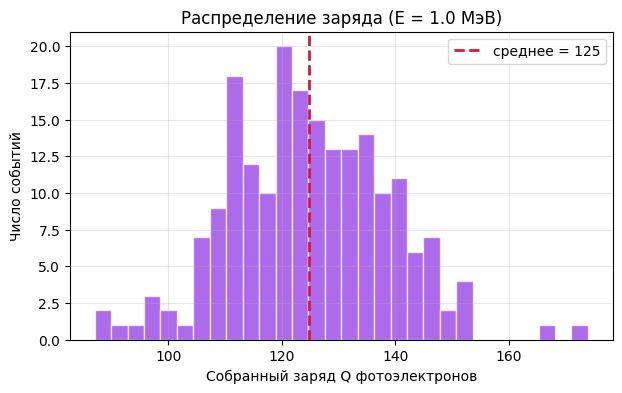

In [14]:
plt.figure(figsize=(7, 4))
plt.hist(charges, bins=30, alpha=0.7, color='blueviolet', edgecolor='white')
plt.axvline(mean_q, color='crimson', linestyle='--', linewidth=2, label=f'среднее = {mean_q:.0f}')
plt.xlabel('Собранный заряд Q фотоэлектронов')
plt.ylabel('Число событий')
plt.title(f'Распределение заряда (E = {E_test} МэВ)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()